# 🃏 The Complete Pokémon TCG Dataset: starter analysis

A reproducible first look at **44,778 Pokémon cards**: the international Trading Card Game from Base Set (1999) to Delta Reign (2026), the **Pokémon TCG Pocket** app, and Japanese and other Asian sets. Fork it, run it top to bottom, and build on it.

**Contents**
1. [Setup and load](#1)
2. [The dataset at a glance](#2)
3. [Cards released per year](#3)
4. [Power creep: HP and damage per Energy](#4)
5. [The rise of rule-box Pokémon](#5)
6. [Card game vs. video game](#6)
7. [The artists](#7)
8. [What cards sell for](#8)
9. [Pokémon TCG Pocket: how rare is a Crown?](#9)
10. [Takeaways and next steps](#10)

> Data: `cards.csv` (one row per card), `card_attacks.csv`, `sets.csv`, `card_pokemon.csv` (cards → National Pokédex numbers), `price_history.csv` (monthly TCGplayer sales, 2022–2024) and `pocket_pull_rates.csv`. Section 6 joins [The Complete Pokédex Dataset](https://www.kaggle.com/datasets/cristobalmitchell/pokedex); add it to the notebook's inputs to run that section.

<a id="1"></a>
## 1. Setup and load

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- the house style of the Pokédex starter notebook -------------------------
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
BLUE, RED = "#2a78d6", "#e34948"
plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 120, "figure.facecolor": "white",
    "axes.facecolor": "white", "axes.edgecolor": GRID, "axes.linewidth": 1,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.titlesize": 14, "axes.titleweight": "bold", "axes.titlecolor": INK,
    "axes.labelcolor": INK2, "text.color": INK, "xtick.color": MUTED,
    "ytick.color": MUTED, "font.size": 11, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
})

def first_existing(*paths):
    return next((Path(p) for p in paths if Path(p).exists()), None)

# On Kaggle the files sit in /kaggle/input/...; locally, run from the repo's notebooks/ folder.
DATA = first_existing("/kaggle/input/pokemon-tcg", "../data", "data")
POKEDEX = first_existing("/kaggle/input/pokedex/pokemon_utf8.csv", "../../pokedex/data/pokemon_utf8.csv")

cards = pd.read_csv(DATA / "cards.csv", low_memory=False)
attacks = pd.read_csv(DATA / "card_attacks.csv")
sets = pd.read_csv(DATA / "sets.csv")
links = pd.read_csv(DATA / "card_pokemon.csv")
prices = pd.read_csv(DATA / "price_history.csv")
pulls = pd.read_csv(DATA / "pocket_pull_rates.csv")
cards["year"] = cards.release_date.str[:4].astype(int)

# Sections 3-7 study the international card game, where every card has English text.
tcg = cards[(cards.region == "international") & (cards.game == "tcg") & (cards.year >= 1999)]
print(cards.shape, tcg.shape)
cards.head(3)

(44778, 39) (21540, 39)


,card_id,set_id,set_name,series,region,game,release_date,number,name,text_language,...,artist,flavor_text,effect,national_numbers,legal_standard,legal_expanded,ptcgio_id,image_url,source,year
0,miscp-001,miscp,Miscellaneous Promos,Miscellaneous,international,tcg,1996-01-01,001,Ancient Mew,en,...,NaN,New Species. Little God or Evil?,NaN,151,False,False,NaN,NaN,tcgdex,1996
1,base1-1,base1,Base Set,Base,international,tcg,1999-01-09,1,Alakazam,en,...,Ken Sugimori,Its brain can outperform a supercomputer. Its ...,NaN,65,False,False,base1-1,https://assets.tcgdex.net/en/base/base1/1/high...,tcgdex,1999
2,base1-2,base1,Base Set,Base,international,tcg,1999-01-09,2,Blastoise,en,...,Ken Sugimori,A brutal Pokémon with pressurized water jets o...,NaN,9,False,False,base1-2,https://assets.tcgdex.net/en/base/base1/2/high...,tcgdex,1999


<a id="2"></a>
## 2. The dataset at a glance

In [2]:
print(f"Cards:          {len(cards):,} in {len(sets)} sets")
print(f"Attacks:        {len(attacks):,}")
print(f"Illustrators:   {cards.artist.nunique():,}")
print(f"Priced cards:   {prices.card_id.nunique():,} ({prices.month.min()} to {prices.month.max()})")
print()
cards.groupby(["region", "game"]).agg(cards=("card_id", "size"), sets=("set_id", "nunique"),
                                      first=("year", "min"), last=("year", "max"))

Cards:          44,778 in 582 sets
Attacks:        54,868
Illustrators:   429
Priced cards:   14,941 (2022-11 to 2024-09)



cards  sets  first  last
region        game                            
asia          tcg     18660   178   1996  2026
international pocket   4577    27   2024  2026
              tcg     21541   205   1996  2026

In [3]:
# Missing values mostly mean "not applicable" (Trainer cards have no HP or attacks).
miss = (tcg.isna().mean() * 100).round(1)
miss[miss > 0].sort_values(ascending=False).to_frame("percent_missing").head(12)

,percent_missing
energy_type,97.5
trainer_type,87.6
suffix,86.9
effect,85.8
resistance_value,76.9
resistance_type,76.9
evolves_from,65.5
evolves_to,62.7
regulation_mark,60.0
flavor_text,51.0


<a id="3"></a>
## 3. Cards released per year

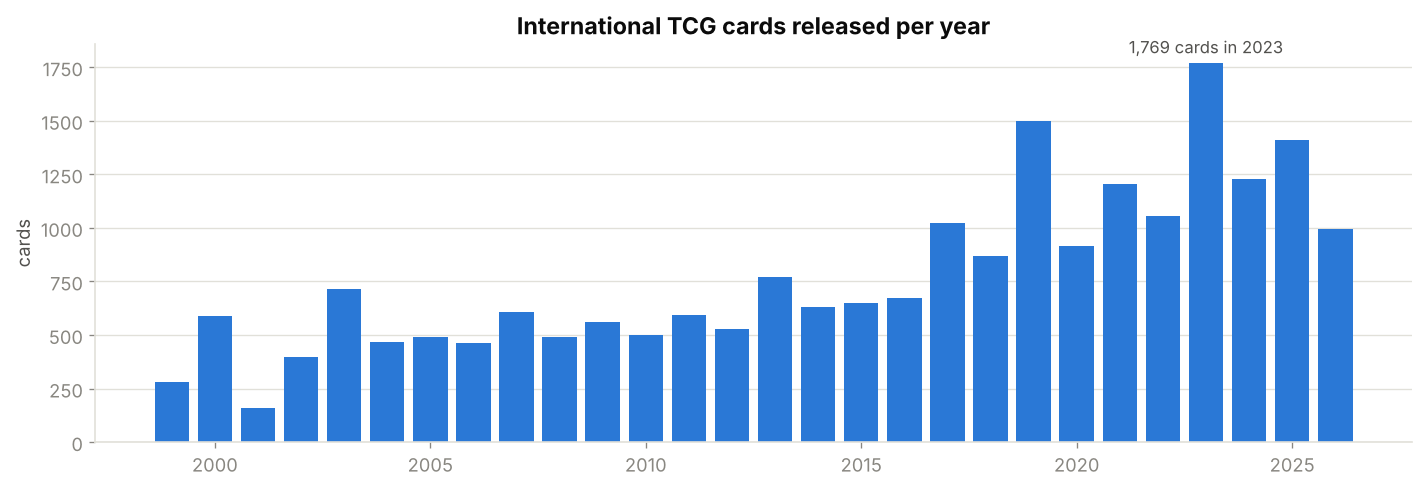

In [4]:
per_year = tcg.groupby("year").size()
fig, ax = plt.subplots(figsize=(12, 4.2))
ax.bar(per_year.index, per_year.values, color=BLUE, width=0.8)
peak = per_year.idxmax()
ax.annotate(f"{per_year.max():,} cards in {peak}", (peak, per_year.max()), xytext=(0, 6),
            textcoords="offset points", ha="center", fontsize=10, color=INK2)
ax.set_title("International TCG cards released per year")
ax.set_ylabel("cards")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

<a id="4"></a>
## 4. Power creep: HP and damage per Energy

Two measures on different scales, so two charts rather than one with two y-axes. Both use the yearly **median**, which is robust to the occasional 300-HP outlier.

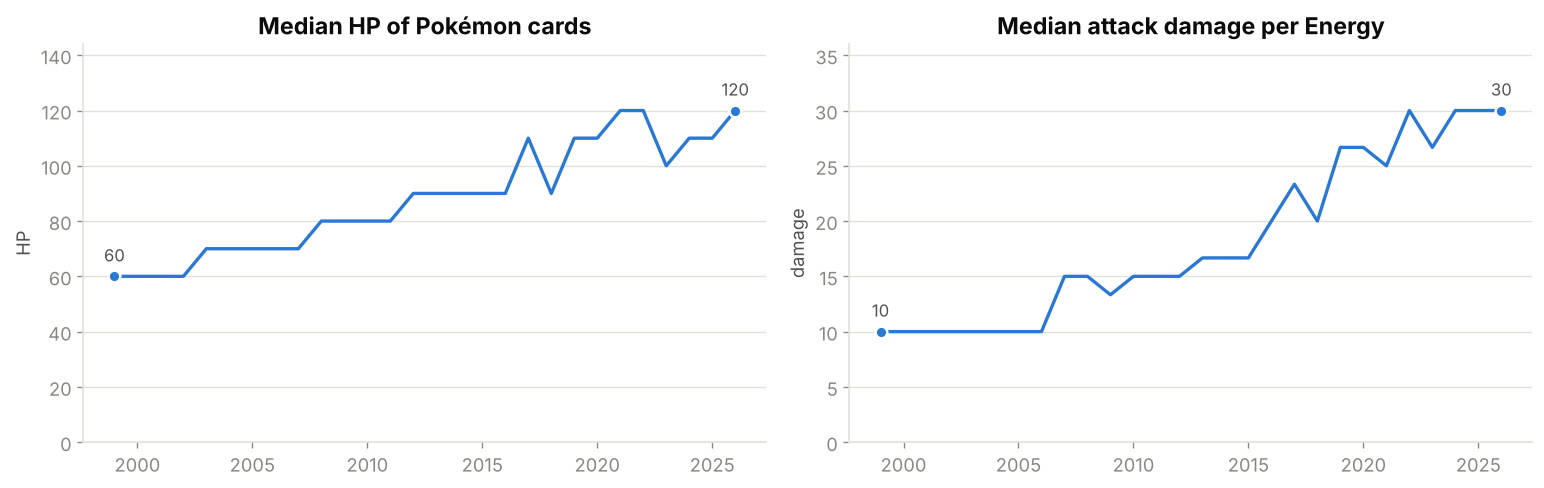

HP: 60 -> 120 (x2.0);  damage per Energy: 10 -> 30 (x3.0)


In [5]:
poke = tcg[tcg.supertype == "Pokémon"].copy()
hp = poke.groupby("year").hp.median()

a = attacks.merge(tcg[["card_id", "year"]], on="card_id")
a = a[(a.converted_energy_cost > 0) & a.base_damage.notna()]
dpe = (a.base_damage / a.converted_energy_cost).groupby(a.year).median()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharex=True)
for ax, s, title, unit in [(axes[0], hp, "Median HP of Pokémon cards", "HP"),
                           (axes[1], dpe, "Median attack damage per Energy", "damage")]:
    ax.plot(s.index, s.values, color=BLUE, linewidth=2)
    ax.plot([s.index[0], s.index[-1]], [s.iloc[0], s.iloc[-1]], "o", color=BLUE, ms=7, mec="white", mew=1.5)
    ax.annotate(f"{s.iloc[0]:.0f}", (s.index[0], s.iloc[0]), xytext=(0, 9), textcoords="offset points",
                ha="center", fontsize=10, color=INK2)
    ax.annotate(f"{s.iloc[-1]:.0f}", (s.index[-1], s.iloc[-1]), xytext=(0, 9), textcoords="offset points",
                ha="center", fontsize=10, color=INK2)
    ax.set_title(title); ax.set_ylabel(unit); ax.set_ylim(0, s.max() * 1.2)
    ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()
print(f"HP: {hp.iloc[0]:.0f} -> {hp.iloc[-1]:.0f} (x{hp.iloc[-1] / hp.iloc[0]:.1f});  "
      f"damage per Energy: {dpe.iloc[0]:.0f} -> {dpe.iloc[-1]:.0f} (x{dpe.iloc[-1] / dpe.iloc[0]:.1f})")

<a id="5"></a>
## 5. The rise of rule-box Pokémon

ex, EX, GX, V, VMAX, VSTAR, TAG TEAM, BREAK, LV.X, LEGEND, Prism Star and Radiant cards carry a **rule box** (e.g. "When your Pokémon ex is Knocked Out, your opponent takes 2 Prize cards"). The `suffix` and `stage` columns identify them. How much of each year's Pokémon cards are these premium cards?

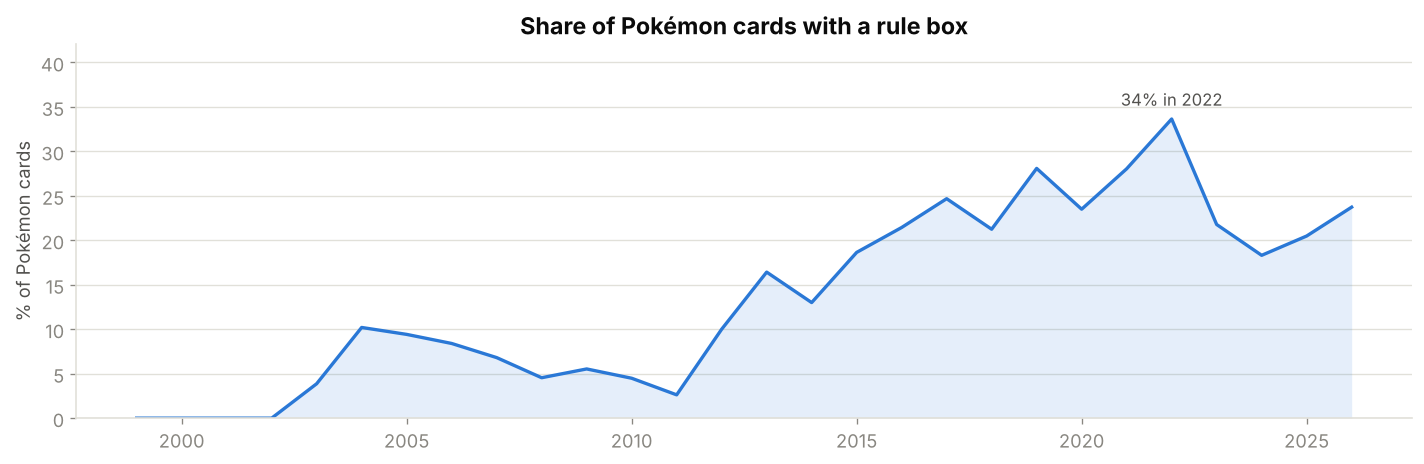

{1999: 0, 2000: 0, 2001: 0, 2002: 0, 2003: 4, 2004: 10, 2005: 9, 2006: 8, 2007: 7, 2008: 5, 2009: 6, 2010: 4, 2011: 3, 2012: 10, 2013: 16, 2014: 13, 2015: 19, 2016: 21, 2017: 25, 2018: 21, 2019: 28, 2020: 23, 2021: 28, 2022: 34, 2023: 22, 2024: 18, 2025: 20, 2026: 24}


In [6]:
RULE_SUFFIX = ["EX", "GX", "TAG TEAM-GX", "V", "ex", "Legend"]
RULE_STAGE = ["VMAX", "VSTAR", "V-UNION", "BREAK", "LEVEL-UP"]
poke["rule_box"] = (poke.suffix.isin(RULE_SUFFIX) | poke.stage.isin(RULE_STAGE)
                    | poke.name.str.contains(r"^Radiant |◇|Prism Star", regex=True))
share = poke.groupby("year").rule_box.mean() * 100

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(share.index, share.values, color=BLUE, linewidth=2)
ax.fill_between(share.index, 0, share.values, color=BLUE, alpha=0.12, linewidth=0)
top = share.idxmax()
ax.annotate(f"{share.max():.0f}% in {top}", (top, share.max()), xytext=(0, 8), textcoords="offset points",
            ha="center", fontsize=10, color=INK2)
ax.set_title("Share of Pokémon cards with a rule box")
ax.set_ylabel("% of Pokémon cards"); ax.set_ylim(0, max(share.max() * 1.25, 10))
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()
print(share.round(0).astype(int).to_dict())

<a id="6"></a>
## 6. Card game vs. video game

Does a Pokémon's HP on cards track its HP stat in the games? Join `card_pokemon.csv` to the Pokédex dataset by National Pokédex number. Only regular cards are used (no rule-box cards, which are built to be bigger), one point per species: its median card HP.

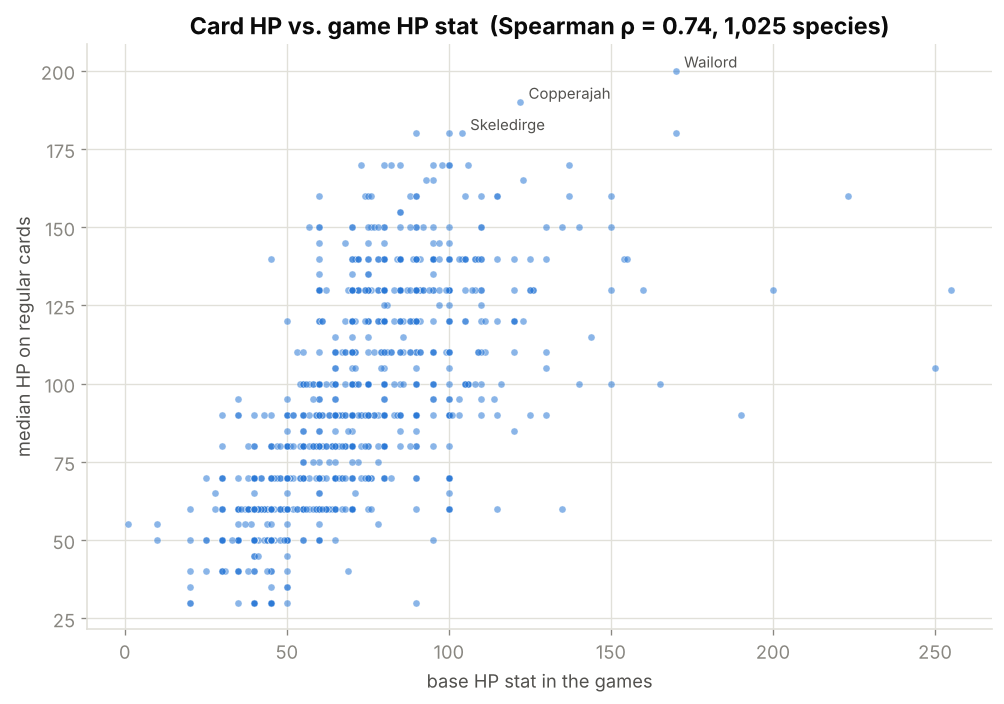

In [7]:
if POKEDEX is None:
    print("Add The Complete Pokédex Dataset (cristobalmitchell/pokedex) to this notebook's inputs to run this section.")
else:
    pokedex = pd.read_csv(POKEDEX)
    featured = links[links.role == "featured"]
    single = featured.groupby("card_id").filter(lambda g: len(g) == 1)       # one Pokémon per card
    regular = poke[~poke.rule_box & poke.hp.notna()][["card_id", "hp"]]
    per_species = (single.merge(regular, on="card_id")
                   .groupby("national_number").hp.median().rename("card_hp").reset_index()
                   .merge(pokedex[["national_number", "english_name", "hp", "is_legendary"]], on="national_number"))
    rho = per_species[["card_hp", "hp"]].corr(method="spearman").iloc[0, 1]

    fig, ax = plt.subplots(figsize=(8.5, 6))
    ax.scatter(per_species.hp, per_species.card_hp, s=18, color=BLUE, alpha=0.55, edgecolors="white", linewidths=0.4)
    for _, r in per_species.nlargest(3, "card_hp").iterrows():
        ax.annotate(r.english_name, (r.hp, r.card_hp), xytext=(5, 2), textcoords="offset points",
                    fontsize=9, color=INK2)
    ax.set_title(f"Card HP vs. game HP stat  (Spearman ρ = {rho:.2f}, {len(per_species):,} species)")
    ax.set_xlabel("base HP stat in the games"); ax.set_ylabel("median HP on regular cards")
    plt.tight_layout(); plt.show()

<a id="7"></a>
## 7. The artists

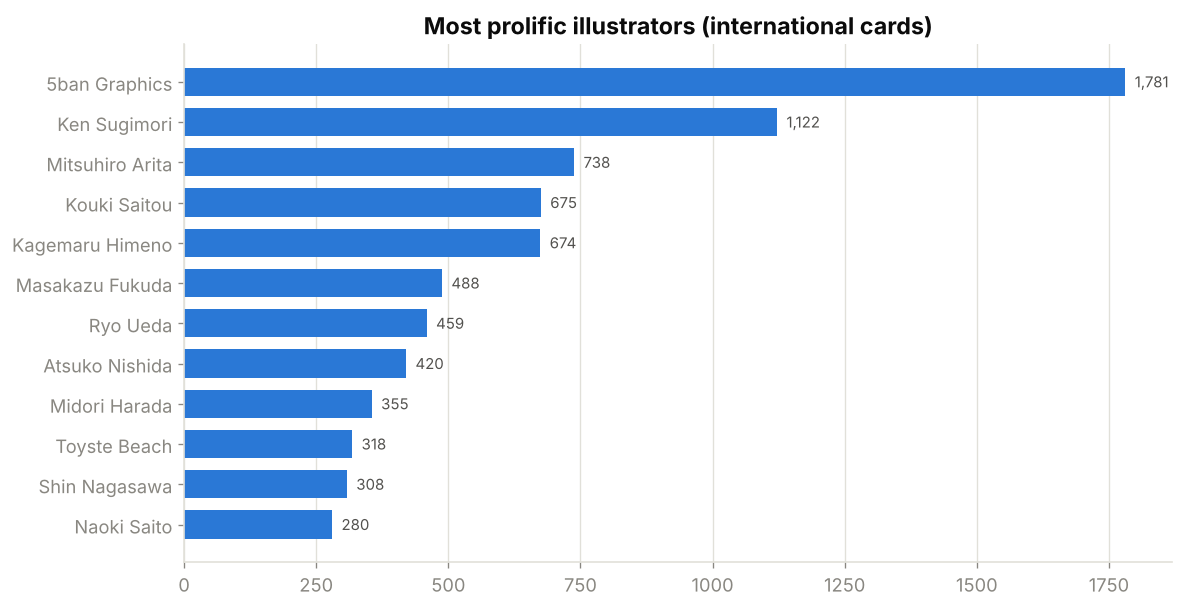

In [8]:
top = tcg.artist.value_counts().head(12).sort_values()
fig, ax = plt.subplots(figsize=(10, 5.2))
ax.barh(top.index, top.values, color=BLUE, height=0.7)
for i, v in enumerate(top.values):
    ax.text(v + top.max() * 0.01, i, f"{v:,}", va="center", fontsize=9, color=INK2)
ax.set_title("Most prolific illustrators (international cards)")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

<a id="8"></a>
## 8. What cards sell for

`price_history.csv` has monthly TCGplayer sale prices from November 2022 to September 2024, per card, finish (normal, reverse, holo) and condition. It is historical: the collector stopped in September 2024. Here, near-mint sales from the last six months of data, for cards of the Scarlet & Violet era.

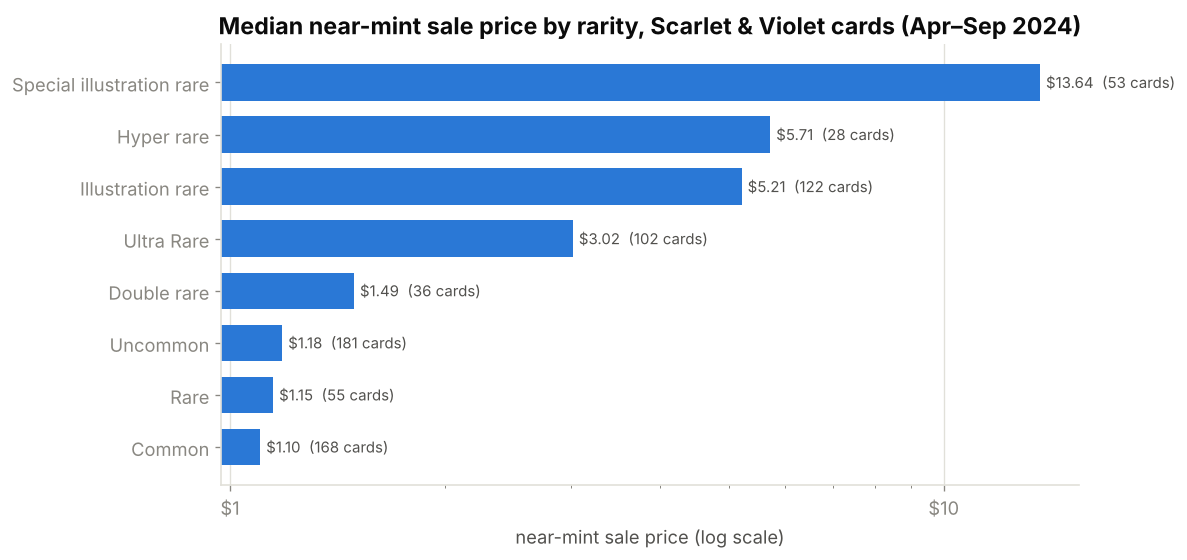

,name,set_name,rarity,price,sales
card_id,,,,,
sv03.5-199,Charizard ex,151,Special illustration rare,119.88,937
sv02-203,Magikarp,Paldea Evolved,Illustration rare,89.86,641
sv02-269,Iono,Paldea Evolved,Special illustration rare,71.56,399
sv04-251,Roaring Moon ex,Paradox Rift,Special illustration rare,58.93,792
sv03.5-200,Blastoise ex,151,Special illustration rare,48.16,1140
sv03-223,Charizard ex,Obsidian Flames,Special illustration rare,44.72,988
sv03.5-198,Venusaur ex,151,Special illustration rare,43.72,1043
sv03.5-202,Zapdos ex,151,Special illustration rare,40.19,1026
sv03.5-183,Charizard ex,151,Ultra Rare,33.92,890


In [9]:
nm = prices[(prices.condition == "nearmint") & (prices.month >= "2024-04")]
per_card = (nm.assign(revenue=nm.avg_price_usd * nm.sales).groupby("card_id")
              .agg(revenue=("revenue", "sum"), sales=("sales", "sum")))
per_card = per_card[per_card.sales >= 3]
per_card["price"] = per_card.revenue / per_card.sales
sv = per_card.join(cards.set_index("card_id")[["name", "set_name", "series", "rarity"]], how="inner")
sv = sv[sv.series == "Scarlet & Violet"]

by_rarity = sv.groupby("rarity").price.agg(["median", "size"])
by_rarity = by_rarity[by_rarity["size"] >= 20].sort_values("median")
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.barh(by_rarity.index, by_rarity["median"], color=BLUE, height=0.7)
for i, (v, n) in enumerate(zip(by_rarity["median"], by_rarity["size"])):
    ax.text(v * 1.02, i, f"${v:,.2f}  ({n:,} cards)", va="center", fontsize=9, color=INK2)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:g}"))
ax.set_title("Median near-mint sale price by rarity, Scarlet & Violet cards (Apr–Sep 2024)")
ax.set_xlabel("near-mint sale price (log scale)")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

sv.nlargest(10, "price")[["name", "set_name", "rarity", "price", "sales"]].round(2)

<a id="9"></a>
## 9. Pokémon TCG Pocket: the rarity ladder

`pocket_pull_rates.csv` gives, for every Pocket set, pack type and card slot, the chance of each rarity. The chance that a pack holds at least one card of a rarity is one minus the chance that no slot does. Genetic Apex, the first set, below.

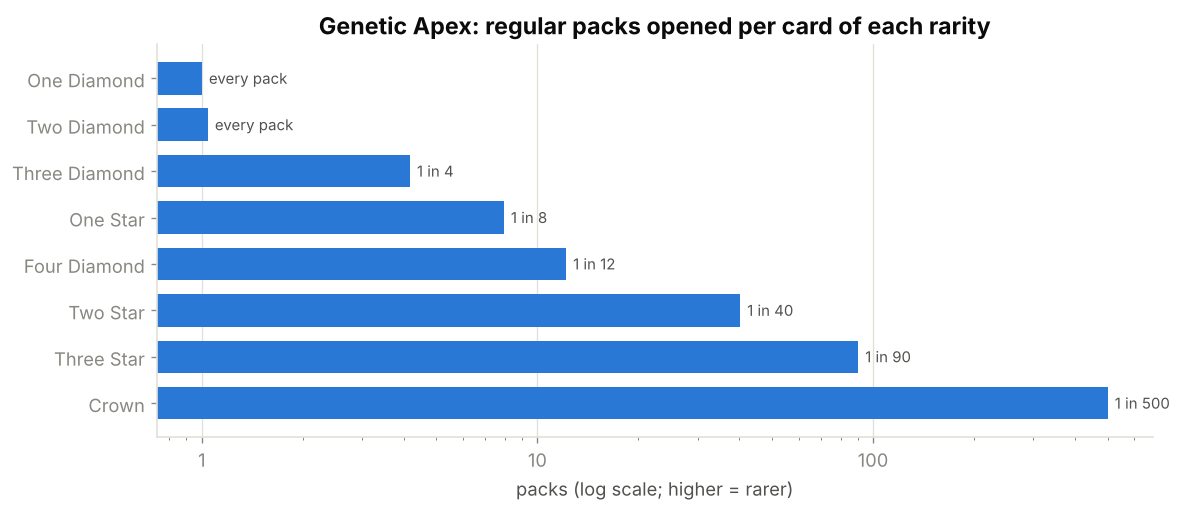

Crown Rare: 1 in 500 to 1 in 505 regular packs across 22 sets
God pack:   [0.05]% of packs (1 in 2,000)


In [10]:
regular = pulls[(pulls.set_id == "A1") & (pulls.pack_type == "Regular Pack")]
p_any = regular.groupby("rarity").rate_pct.apply(lambda r: 1 - np.prod(1 - r / 100)).sort_values(ascending=False)
packs = 1 / p_any

fig, ax = plt.subplots(figsize=(10, 4.4))
ax.barh(packs.index[::-1], packs.values[::-1], color=BLUE, height=0.7)
for i, v in enumerate(packs.values[::-1]):
    ax.text(v * 1.05, i, f"1 in {v:,.0f}" if v >= 2 else "every pack", va="center", fontsize=9, color=INK2)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_title("Genetic Apex: regular packs opened per card of each rarity")
ax.set_xlabel("packs (log scale; higher = rarer)")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

# The same ladder holds in every set; the rare "god pack" replaces a regular pack this often:
god = pulls[pulls.pack_type == "Rare Pack"].groupby("set_id").pack_rate_pct.first()
crown = (pulls[(pulls.pack_type == "Regular Pack") & (pulls.rarity == "Crown")].groupby("set_id").rate_pct
         .apply(lambda r: 1 / (1 - np.prod(1 - r / 100))))
print(f"Crown Rare: 1 in {crown.min():,.0f} to 1 in {crown.max():,.0f} regular packs across {len(crown)} sets")
print(f"God pack:   {god.unique()}% of packs (1 in {100 / god.median():,.0f})")

<a id="10"></a>
## 10. Takeaways and next steps

- **Power creep is real and measurable:** between 1999 and 2026 the median HP of Pokémon cards doubled (60 → 120) and the median attack damage per Energy tripled (10 → 30).
- **Premium rule-box cards** were absent until the ex era (up to 10% of Pokémon cards in 2004) and have been between 18% and 34% of them every year since 2015 (peak in 2022).
- **Card HP follows the games:** across all 1,025 species, median card HP and the HP stat have a Spearman rank correlation of 0.74.
- **Rarity drives price:** among Scarlet & Violet cards with at least three near-mint sales in Apr–Sep 2024, the median Special Illustration Rare sold for about $14, twelve times a Common's $1.10. The 151 Charizard ex Special Illustration Rare led at about $120.
- **Pocket's ladder is the same in every set:** a regular pack holds a Crown Rare 1 time in 500 and a three-star card 1 time in 90, and 1 pack in 2,000 is a "god pack".


**Ideas to take further**
- Model card HP from game stats, typing and evolution stage (regression).
- Forecast or explain prices: rarity, artist, Pokémon popularity (join the Pokédex dataset's Smogon usage) and set age.
- Cluster attacks by cost, damage and text into archetypes (NLP + clustering).
- Compare a Japanese set with its English release (`region`, `card_names.csv`).
- Track how rarity names changed: Rare Holo → Ultra Rare → Illustration Rare → Special Illustration Rare.
- Query everything with SQL in `tcg.sqlite`.

*If this helped, an upvote is appreciated. Tell me in the comments what you'd like analysed next.*